# 04. 可視化・SHAP分析

## 概要
03_modeling.ipynbで確定したRound5の最終モデル
（multilingual-e5-large-instruct + UMAP + HDBSCAN）の
クラスタリング結果を可視化し、SHAP/LIMEで解釈する。

## 入力
- `data/speeches_clustered.csv`
- `data/embeddings_round5.npy`
- `data/umap_round5.npy`

## 出力
- クラスタの2次元可視化
- 少数派クラスタのハイライト
- クラスタ代表発言の抽出
- SHAP/LIMEによる特徴説明

In [12]:
# ============================================================
# ライブラリのインポートとデータ読み込み
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import umap
import hdbscan
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

# 日本語フォント設定
font_path = "/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/japanize_matplotlib/fonts/ipaexg.ttf"
fm.fontManager.addfont(font_path)
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "IPAexGothic"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (12, 6)

# データ読み込み
df = pd.read_csv("../data/speeches_clustered.csv")
embeddings_r5 = np.load("../data/embeddings_round5.npy")
umap_r5 = np.load("../data/umap_round5.npy")

print(f"データ数: {len(df)}件")
print(f"埋め込み形状: {embeddings_r5.shape}")
print(f"UMAP形状: {umap_r5.shape}")

データ数: 6301件
埋め込み形状: (6301, 1024)
UMAP形状: (6301, 10)


## 1. クラスタリング結果の2次元可視化
UMAPで2次元に圧縮してクラスタを可視化する。
少数派クラスタをハイライト表示する。

In [13]:
# ============================================================
# UMAPで2次元に圧縮して可視化
# ============================================================

# 2次元UMAPを計算（可視化用）
reducer_2d = umap.UMAP(n_components=2, n_neighbors=15,
                       min_dist=0.1, random_state=42)
embeddings_2d = reducer_2d.fit_transform(normalize(embeddings_r5))

# クラスタラベル
labels = df["cluster_r5"].values

# 少数派クラスタの定義（200件以下）
cluster_sizes = df["cluster_r5"].value_counts()
minority_clusters = cluster_sizes[
    (cluster_sizes.index != -1) & (cluster_sizes < 200)
].index.tolist()

print(f"少数派クラスタ: {minority_clusters}")
print(f"少数派クラスタの件数: {cluster_sizes[minority_clusters].to_dict()}")

少数派クラスタ: [13, 3, 22, 20, 7, 16, 2, 12, 21, 6, 1, 14, 8, 11, 9, 18, 17, 19, 10]
少数派クラスタの件数: {13: 170, 3: 159, 22: 152, 20: 144, 7: 136, 16: 117, 2: 117, 12: 102, 21: 97, 6: 97, 1: 95, 14: 91, 8: 74, 11: 65, 9: 58, 18: 57, 17: 56, 19: 54, 10: 51}


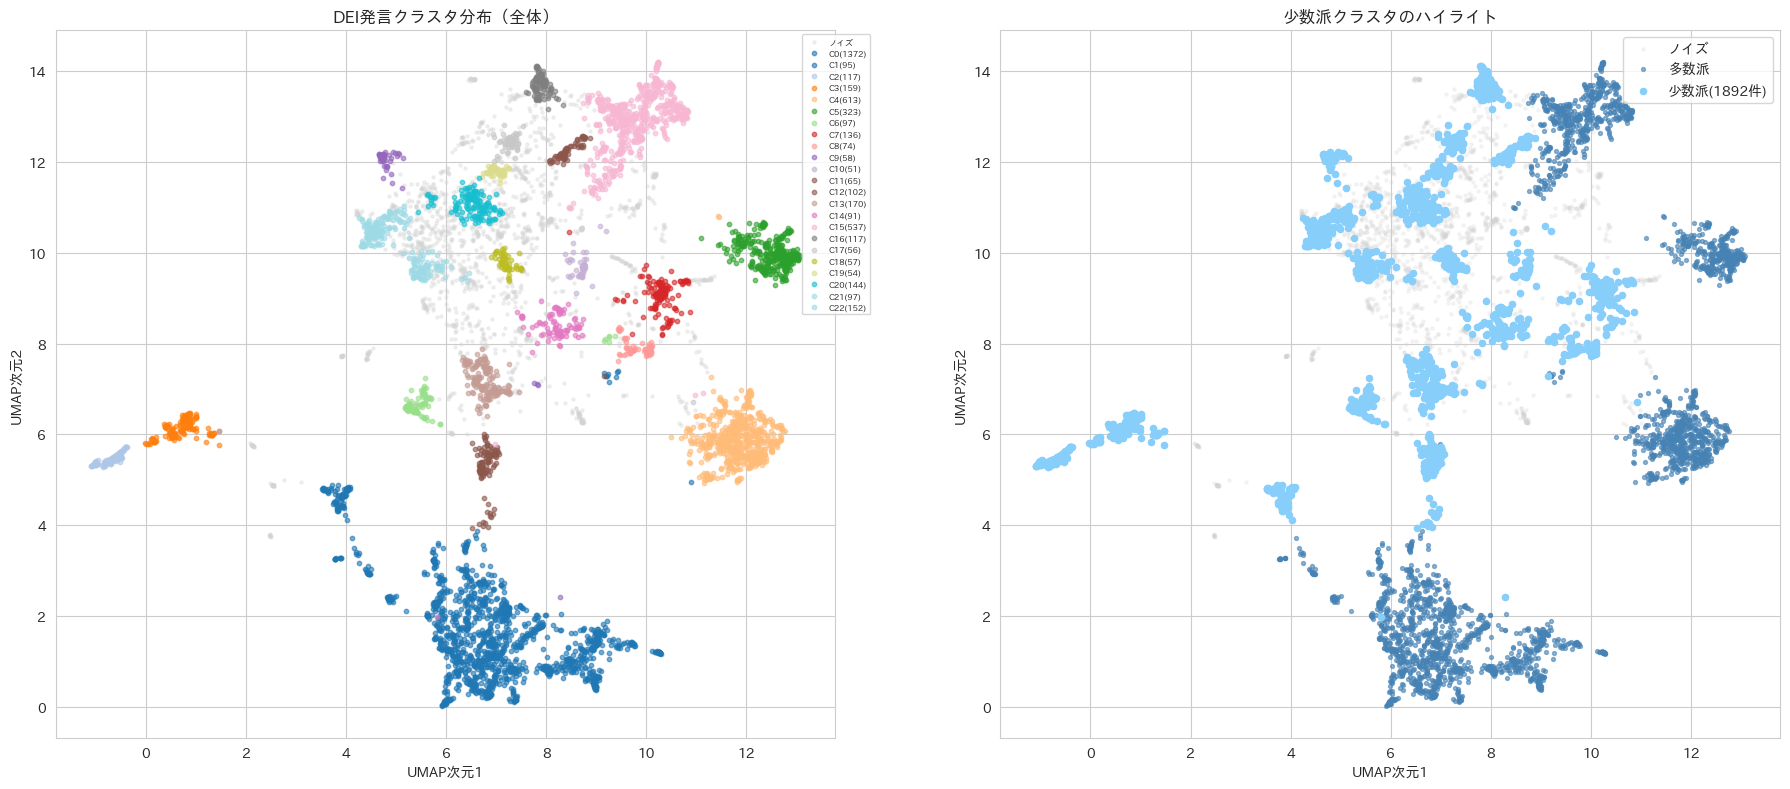

保存完了: ../data/cluster_visualization.png


In [36]:
# ============================================================
# 2次元UMAP可視化（クラスタ色分け・少数派ハイライト）
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- 左：全クラスタ色分け ---
noise_mask = labels == -1
axes[0].scatter(embeddings_2d[noise_mask, 0], embeddings_2d[noise_mask, 1],
                c="lightgray", s=5, alpha=0.3, label="ノイズ")

unique_clusters = sorted([c for c in np.unique(labels) if c != -1])
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_clusters)))
for cluster, color in zip(unique_clusters, colors):
    mask = labels == cluster
    axes[0].scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                    c=[color], s=10, alpha=0.6, label=f"C{cluster}({mask.sum()})")

axes[0].set_title("DEI発言クラスタ分布（全体）")
axes[0].set_xlabel("UMAP次元1")
axes[0].set_ylabel("UMAP次元2")
axes[0].legend(bbox_to_anchor=(1.05, 1), fontsize=6)

# --- 右：少数派ハイライト ---
axes[1].scatter(embeddings_2d[noise_mask, 0], embeddings_2d[noise_mask, 1],
                c="lightgray", s=5, alpha=0.2, label="ノイズ")

majority_clusters = [c for c in unique_clusters if c not in minority_clusters]
for cluster in majority_clusters:
    mask = labels == cluster
    axes[1].scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                    c="steelblue", s=8, alpha=0.6, label="多数派" if cluster == majority_clusters[0] else "")

minority_mask = np.isin(labels, minority_clusters)
axes[1].scatter(embeddings_2d[minority_mask, 0], embeddings_2d[minority_mask, 1],
                c="lightskyblue", s=20, alpha=1.0, label=f"少数派({minority_mask.sum()}件)")

axes[1].set_title("少数派クラスタのハイライト")
axes[1].set_xlabel("UMAP次元1")
axes[1].set_ylabel("UMAP次元2")
axes[1].legend()

plt.tight_layout()
plt.savefig("../data/cluster_visualization.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/cluster_visualization.png")

### 可視化結果の考察
- クラスタが空間的にきれいに分離されており、高いシルエットスコア（0.7498）と一致
- 左下の大きなクラスタ（C0: 1,372件）が多数派の意見グループ
- 少数派クラスタ（ライトブルー・1,892件）は空間的に分散しており
  多数派とは異なる意見・トピックを持つグループが存在することが視覚的に確認できる
- HDBSCANが多数決的判断に頼らず少数派を独立したグループとして検出できている

## 2. クラスタの内容分析
各クラスタの代表発言を抽出してDEIのどの側面を扱っているか確認する。

In [15]:
# ============================================================
# 各クラスタの代表発言を抽出（クラスタ中心に最も近い発言）
# ============================================================

cluster_labels = sorted([c for c in df["cluster_r5"].unique() if c != -1])
cluster_summaries = []

for cluster in cluster_labels:
    cluster_df = df[df["cluster_r5"] == cluster]
    # クラスタ内の発言をサンプル表示（最初の1件）
    sample = cluster_df["speech_clean"].iloc[0][:200]
    keyword = cluster_df["keyword"].iloc[0]
    cluster_summaries.append({
        "cluster": cluster,
        "件数": len(cluster_df),
        "代表キーワード": keyword,
        "代表発言（冒頭200文字）": sample
    })

summary_df = pd.DataFrame(cluster_summaries)
pd.set_option("display.max_colwidth", 100)
print(summary_df.to_string(index=False))

 cluster   件数    代表キーワード                                                                                                                                                                                            代表発言（冒頭200文字）
       0 1372        多様性 ありがとうございます。 実は、私、杉並区で議員をやっていたことがありまして、そのときにレジ袋税というのが大変議論されたことがありました。このときに、その議論の収れんのときに、レジ袋は環境にはプラスにならないだろう、だから減らすために力を尽くすのはこれは正義じゃないかということで議論が収れんしていったのであります。 ということで、やはり、ごみに出さない、使い捨てにしない、こういったことを徹底させてい
       1   95      障害者雇用 これより会議を開きます。 国土交通行政の基本施策に関する件について調査を進めます。 この際、お諮りいたします。 本件調査のため、本日、参考人として中日本高速道路株式会社代表取締役社長宮池克人君の出席を求め、意見を聴取することとし、また、政府参考人として国土交通省総合政策局長石田優君、不動産・建設経済局長青木由行君、水管理・国土保全局長井上智夫君、道路局長吉岡幹夫君、住宅局長和田信貴君、鉄道局長上原
       2  117      障害者雇用 令和七年三月二十八日（金曜日） 午前八時五十七分開会 ───────────── 委員の異動 三月二十七日 辞任 補欠選任 田中 昌史君 堀井 巌君 山田 宏君 古川 俊治君 小沼 巧君 吉川 沙織君 奥村 政佳君 水岡 俊一君 下野 六太君 秋野 公造君 片山 大介君 柳ヶ瀬裕文君 田村 まみ君 礒崎 哲史君 吉良よし子君 仁比 聡平君 三月二十八日 辞任 補欠選任 江島 潔君 神谷 政幸君 佐
       3  159      障害者雇用 よろしくお願いいたします。三十分間、質問させていただきます。 冒頭はちょっとお茶の健康効果のことを聞きたいんですが、後半は、生活困窮者という視

### クラスタ内容分析結果

| クラスタ | 件数 | 主なトピック |
|---------|------|------------|
| C0 | 1,372 | 多様性（一般・環境政策等）|
| C1 | 95 | 障害者雇用・国土交通 |
| C2 | 117 | 障害者雇用・議事進行 |
| C3 | 159 | 障害者雇用・生活困窮者支援 |
| C4 | 613 | 外国人労働者・在留資格 |
| C5 | 323 | 障害者支援法・誰一人取り残さない社会 |
| C6 | 97 | ジェンダーバランス・審議会人選 |
| C7 | 136 | 教育における多様性 |
| C8 | 74 | 理工系・基礎研究・多様性 |
| C9 | 58 | ダイバーシティ・ハラスメント対策 |
| C10 | 51 | 理工系女性活躍・入学者選抜 |
| C11 | 65 | LGBT・東京五輪・多様性と調和 |
| C12 | 102 | 多様性・国際関係（インド・グローバルサウス）|
| C13 | 170 | 多様性・教育（空調整備等）|
| C14 | 91 | ジェンダーフリー・企業イメージ |
| C15 | 537 | LGBT理解増進法・ジェンダー |
| C16 | 117 | 女性活躍・男女共同参画・国際社会 |
| C17 | 56 | ジェンダーギャップ指数・CEDAW |
| C18 | 57 | 女性活躍・地方創生 |
| C19 | 54 | ジェンダー平等・G7・国際連携 |
| C20 | 144 | 女性活躍・予算委員会 |
| C21 | 97 | 育児・介護休業法・多様性 |
| C22 | 152 | 女性活躍・地方公務員給与格差 |

**少数派クラスタの注目点**
- C10（51件）：理工系女性活躍・入学者選抜の多様性確保
- C17（56件）：ジェンダーギャップ指数・国連CEDAW対日審査
- C19（54件）：G7・国際的なジェンダー平等への取組
- C11（65件）：LGBT・東京五輪における多様性と調和

これらは件数は少ないが**具体的かつ専門的なDEIトピック**を扱っており
多数決的な分析では埋もれてしまう可能性がある重要な少数意見である。

### 例１：C4（外国人労働者クラスタ）の発言内容確認
代表発言だけでなく実際のサンプルを確認してクラスタの内容を検証する。

In [16]:
# C4（外国人労働者クラスタ）の発言をサンプル確認
c4_samples = df[df["cluster_r5"] == 4]["speech_clean"].sample(5, random_state=42)
for i, text in enumerate(c4_samples):
    print(f"--- {i+1}件目 ---")
    print(text[:200])
    print()

--- 1件目 ---
お答えいたします。 出入国在留管理庁におきましては、昨年四月二十日から、新型コロナウイルス感染症の感染拡大の影響により解雇等され、実習実施が困難となりました技能実習生、解雇等され、就労の継続が困難となりました外国人労働者、さらには、採用内定を取り消された留学生を対象といたしまして、本邦での継続した就労を可能とするため、一定の条件の下で就労が可能な特定活動への在留資格の変更を認める特例措置を講じてい

--- 2件目 ---
よろしくお願いいたします。 私の方からは、こちらのスライドにもあるように、外国人の高齢化と社会保障、そして、私自身社会福祉を専門としておりますので、社会福祉制度などについても述べたいと思います。（資料映写） 特に、社会保障の検討の観点から見た外国人の概況、そして現状としての社会保障や社会福祉制度の適用状況、そして今後の課題について述べたいと思います。 社会保障制度を考える上で、外国の方がどういった

--- 3件目 ---
是非検討をして進めていただきたいと思います。 というのも、関係者ヒアリングというのも支援団体や受入れ事業者が中心であって、一般の国民の声が十分反映されているとは思えません。 この点、ハーバード大学の政治学者であるロバート・パットナム氏の多様性と信頼の低下の研究によりますと、人種多様化が人種間のみならず人種内でも共同体メンバー間の信頼を低下させるとの論文が発表されており、治安の悪化や分断につながった

--- 4件目 ---
ありがとうございます。 是非、中央建設業審議会において、多方面にわたる関係者の皆さんがこの審議会には参画されるというのは午前中の御答弁でもありましたので、しっかりいろんな方の意見聞きながら、やっぱり現場が使える、そして行き渡って実効性あるものにしていくというのが本当に大事だというのは、参考人の皆さんからも本当そういう意見、我々も伺いましたので、是非しっかりとした標準労務費となるように、今後の議論に

--- 5件目 ---
まず、この有識者会議においては、外国人の日本語能力の向上に向けた取組、これを論点の一つとして議論しているということです。 それで、この有識者会議の中でも、委員と同様の問題意識だと私は感じるんですけれども、企業と外国人本人の双方にとって日本語を学ぶことがプラスになる

## 3. SHAP分析
クラスタ分類の根拠をSHAPで解釈する。
少数派クラスタと多数派クラスタの違いを説明する。

In [17]:
# ============================================================
# SHAP分析：クラスタ分類の特徴を解釈する
# UMAPの10次元埋め込みをSVMで分類してSHAPで解釈
# ============================================================
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
import shap

# ノイズを除外
df_clean = df[df["cluster_r5"] != -1].copy()
X = umap_r5[df["cluster_r5"] != -1]
y = df_clean["cluster_r5"].values

# 少数派vs多数派の2値分類
df_clean["is_minority"] = df_clean["cluster_r5"].isin(minority_clusters).astype(int)
y_binary = df_clean["is_minority"].values

# SVMで学習
print("SVMで学習中...")
clf = SVC(kernel="rbf", probability=True, random_state=42)
clf.fit(X, y_binary)
print(f"学習完了・精度: {clf.score(X, y_binary):.4f}")

SVMで学習中...
学習完了・精度: 0.9888


### SVM（サポートベクターマシン）学習結果
- 精度：0.9888（98.88%）
- "少数派"と"多数派"がUMAP空間でほぼ完全に分離できていることを示す
- これはクラスタリングの質が高い（シルエットスコア0.7498）ことと一致する

## 3. SHAP分析
クラスタ分類の根拠をSHAPで解釈する。
少数派クラスタと多数派クラスタの違いをUMAP次元の重要度で説明する。

### 分析方針
- UMAP10次元の埋め込みを特徴量としてSVMで少数派/多数派を分類
- SHAPでどのUMAP次元が少数派の判定に寄与しているかを可視化

  0%|          | 0/200 [00:00<?, ?it/s]

shap_values type: <class 'numpy.ndarray'>
shap_values shape: (200, 10, 2)


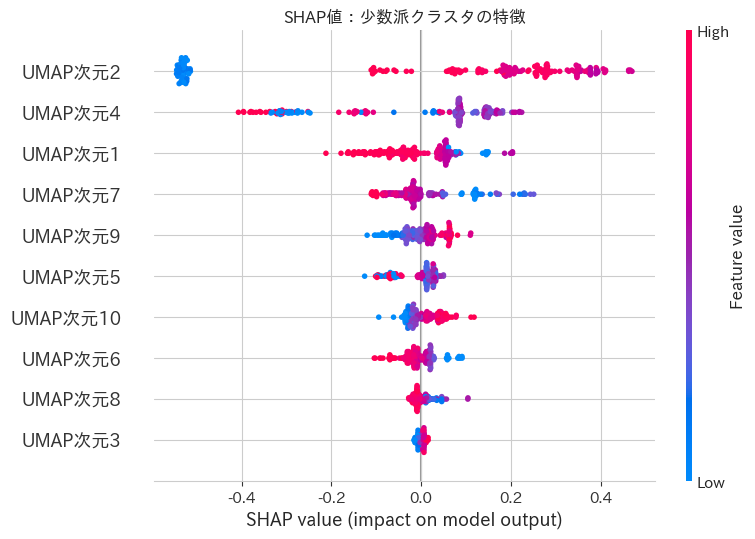

保存完了: ../data/shap_summary.png


In [19]:
# ============================================================
# SHAPで特徴量の重要度を可視化
# ============================================================

sample_X = shap.sample(X, 200, random_state=42)
explainer = shap.KernelExplainer(clf.predict_proba, shap.sample(X, 100, random_state=42))
shap_values = explainer.shap_values(sample_X)

# shap_valuesの形状確認
print(f"shap_values type: {type(shap_values)}")
print(f"shap_values shape: {np.array(shap_values).shape}")

feature_names = [f"UMAP次元{i+1}" for i in range(X.shape[1])]

# 少数派クラス（index=1）のSHAP値を可視化
shap.summary_plot(
    shap_values[:, :, 1] if np.array(shap_values).ndim == 3 else shap_values[1],
    sample_X,
    feature_names=feature_names,
    show=False
)
plt.title("SHAP値：少数派クラスタの特徴")
plt.tight_layout()
plt.savefig("../data/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/shap_summary.png")

In [20]:
# ============================================================
# UMAP次元2が高い発言と低い発言を確認して考察の根拠を作る
# ============================================================

# UMAP次元2の値をdfに追加
df_clean2 = df[df["cluster_r5"] != -1].copy()
df_clean2["umap_dim2"] = umap_r5[df["cluster_r5"] != -1, 1]

# 次元2が高い発言トップ5
print("=== UMAP次元2が高い発言（少数派寄り）===")
top5 = df_clean2.nlargest(5, "umap_dim2")[["speech_clean", "keyword", "cluster_r5"]]
for i, row in top5.iterrows():
    print(f"クラスタ{row['cluster_r5']} | {row['keyword']}")
    print(row["speech_clean"][:150])
    print()

print("=== UMAP次元2が低い発言（多数派寄り）===")
bot5 = df_clean2.nsmallest(5, "umap_dim2")[["speech_clean", "keyword", "cluster_r5"]]
for i, row in bot5.iterrows():
    print(f"クラスタ{row['cluster_r5']} | {row['keyword']}")
    print(row["speech_clean"][:150])
    print()

=== UMAP次元2が高い発言（少数派寄り）===
クラスタ5 | 女性活躍
企業規模等に応じて制度をいろいろ運営しているのはいろいろあります。私どもの関係でも、例えば女性活躍推進法等々の適用対象、あるいは先般御議論いただきました被用者保険の適用対象について、これ例えば五百人とか五十人とかさせていただいている。これは、それぞれの趣旨、目的にのっとって規模を決定させていただいて

クラスタ5 | 障害者雇用
雇用率制度でございますが、社会連帯の理念の下で、全ての事業主に対して、その雇用する労働者の数に応じて一定割合の障害者雇用を義務づけるものであり、五年に一度、設定をしております。現在既に、令和九年度、二〇二七年度までの雇用率が決定しており、まずは、その雇用率の達成に向けて企業等における障害者雇用の取組

クラスタ5 | 障害者雇用
お答えいたします。 障害者雇用促進法では、全ての事業主に雇用率制度による雇用義務を課すとともに、社会連帯の理念に基づきまして、障害者に雇用の場を提供する事業主の社会的な責任の履行を確保するために、経済的側面からの負担の調整として納付金制度を設けておるところでございます。 具体的には、法定雇用率が未達

クラスタ5 | 障害者雇用
障害者雇用納付金に対しての納付金の猶予があるかということでございますけれども、事業主からの申請に基づきまして、令和二年二月一日から令和三年一月三十一日までに納付期限が到来する納付金を対象に、障害者雇用納付金の納付を一年以内に限り猶予する措置を講じております。

クラスタ5 | 障害者雇用
障害者雇用促進法では、社会連帯の理念の下で、全ての事業主に対して、その雇用する労働者の数に応じて一定割合の障害者雇用を義務づけるとともに、雇用義務を果たしていない事業主から、障害者の不足数に応じて障害者雇用納付金を徴収する仕組みを設けております。 障害者雇用納付金に関する現行の取扱いとして、企業規模

=== UMAP次元2が低い発言（多数派寄り）===
クラスタ0 | 多様性
お答えいたします。 有機農産物等を学校給食で活用することは、有機農業が生物多様性の保全など環境保全に貢献する取組であることを児童や生徒を通じて親御さん、それから地域住民の理解を得ていくということ、それから、地域で安定した消費、つまり供給先を確保して、有

### SHAP分析結果

#### SHAPグラフの見方
- **縦軸**：特徴量（UMAP次元1〜10）。上にあるほど少数派/多数派の判定に重要
- **横軸**：SHAP値。右（プラス）→少数派と判定される方向、左（マイナス）→多数派と判定される方向
- **点の色**：赤（その次元の値が高い）、青（その次元の値が低い）

#### 考察
- **UMAP次元2**が少数派クラスタの判定に最も重要な次元
  - 次元2が高い発言：障害者雇用率制度・納付金など**制度の具体的な数値・義務規定**に関する発言が多い
  - 次元2が低い発言：生物多様性・有機農業・SDGsなど**環境・農業文脈での多様性**が多い
  - → 「多様性」という言葉の使われ方の違いをUMAP次元2が捉えている
- **UMAP次元4**は値が低いほど少数派に寄与
- **UMAP次元1**は値が高いほど多数派に寄与
- UMAP次元2・4が少数派の意見空間を主に規定していると解釈できる

## 4. LIME分析
個別発言に対してLIMEで分類根拠を説明する。
多数派・少数派それぞれの代表発言を比較することで、
どのような発言が少数派として判定されるかを明らかにする。

【多数派代表発言（クラスタ0）】
ありがとうございます。 実は、私、杉並区で議員をやっていたことがありまして、そのときにレジ袋税というのが大変議論されたことがありました。このときに、その議論の収れんのときに、レジ袋は環境にはプラスにならないだろう、だから減らすために力を尽くすのはこれは正義じゃないかということで議論が収れんしていったのであります。 ということで、やはり、ごみに出さない、使い捨てにしない、こういったことを徹底させてい

【少数派代表発言（クラスタ17）】
どうもありがとうございます。 今、ジェンダーギャップ指数とそれから国連の女性差別撤廃委員会の二つの対日審査、ある意味では評価についてのお話を伺ったんですけれども、国際的な観点から見た日本の評価というのは実はかなりつながっているというふうに思っています。 具体的にはどういうことかといいますと、今回のＣＥＤＡＷの対日審査の中には、喫緊に、二年以内に重要な課題に関して報告をすることというのが四項目挙がっ



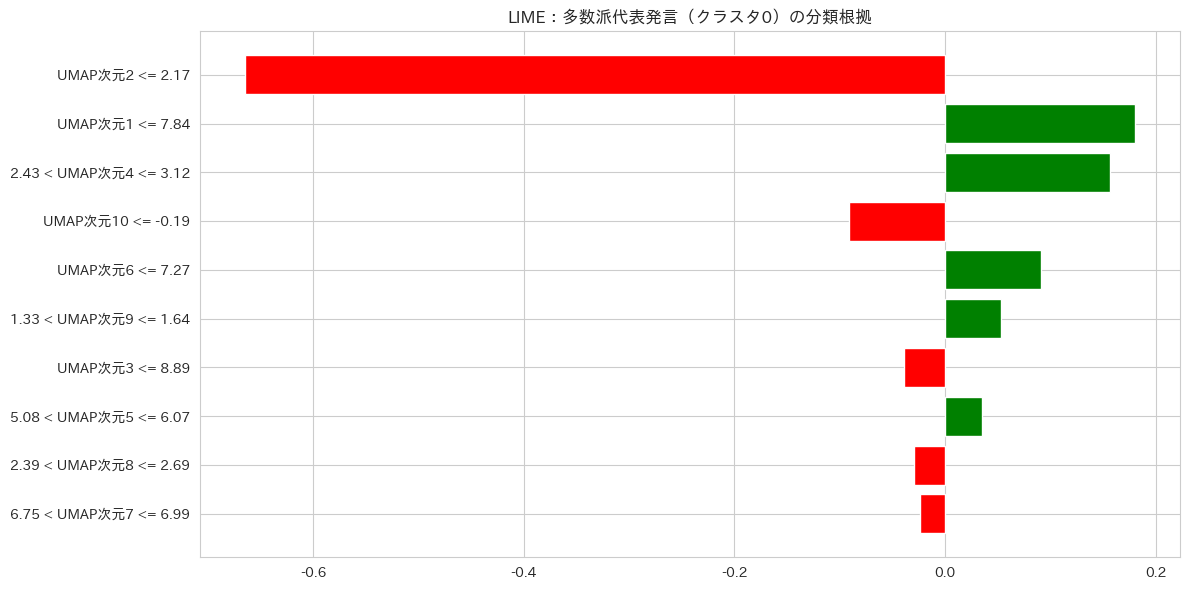

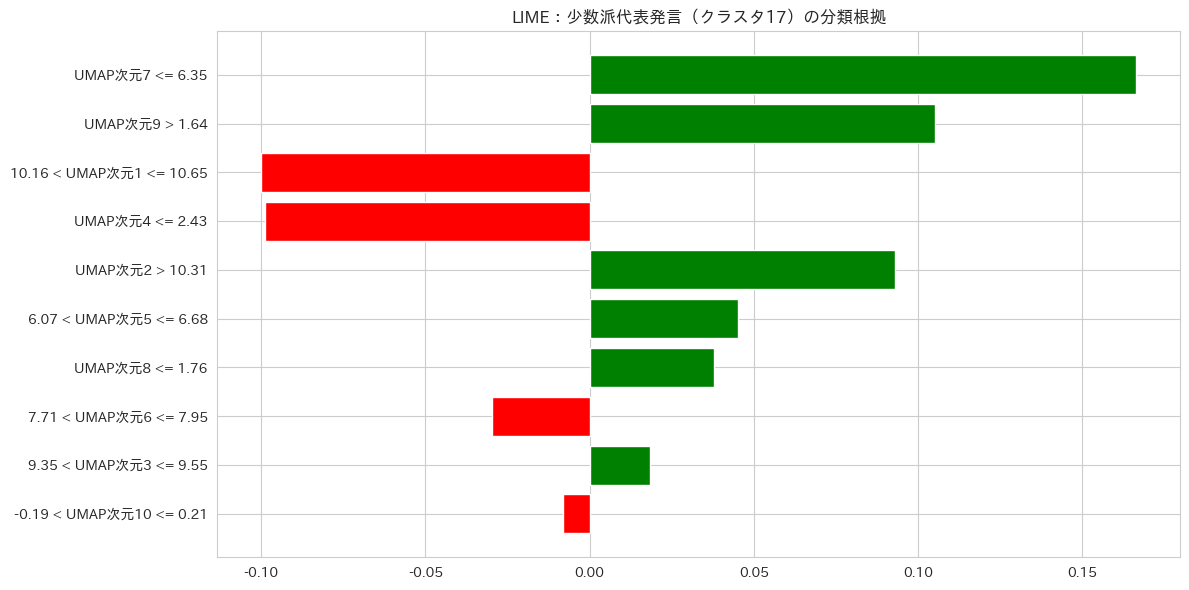

保存完了: ../data/lime_majority.png
保存完了: ../data/lime_minority.png


In [24]:
# ============================================================
# LIME分析：多数派・少数派それぞれの代表発言の分類根拠を比較
# ============================================================
from lime.lime_tabular import LimeTabularExplainer

explainer_lime = LimeTabularExplainer(
    X,
    feature_names=[f"UMAP次元{i+1}" for i in range(X.shape[1])],
    class_names=["多数派", "少数派"],
    mode="classification",
    random_state=42
)

# --- 多数派代表（クラスタ0：最大クラスタ） ---
target_majority = df_clean[df_clean["cluster_r5"] == 0].index[0]
pos_majority = np.where(df_clean.index == target_majority)[0][0]
print("【多数派代表発言（クラスタ0）】")
print(df_clean.loc[target_majority, "speech_clean"][:200])
print()

exp_majority = explainer_lime.explain_instance(
    X[pos_majority], clf.predict_proba, num_features=10
)

# --- 少数派代表（クラスタ17：ジェンダーギャップ指数） ---
target_minority = df_clean[df_clean["cluster_r5"] == 17].index[0]
pos_minority = np.where(df_clean.index == target_minority)[0][0]
print("【少数派代表発言（クラスタ17）】")
print(df_clean.loc[target_minority, "speech_clean"][:200])
print()

exp_minority = explainer_lime.explain_instance(
    X[pos_minority], clf.predict_proba, num_features=10
)

# 多数派のLIME可視化
fig1 = exp_majority.as_pyplot_figure()
plt.title("LIME：多数派代表発言（クラスタ0）の分類根拠")
plt.tight_layout()
plt.savefig("../data/lime_majority.png", dpi=150, bbox_inches="tight")
plt.show()

# 少数派のLIME可視化
fig2 = exp_minority.as_pyplot_figure()
plt.title("LIME：少数派代表発言（クラスタ17）の分類根拠")
plt.tight_layout()
plt.savefig("../data/lime_minority.png", dpi=150, bbox_inches="tight")
plt.show()

print("保存完了: ../data/lime_majority.png")
print("保存完了: ../data/lime_minority.png")

### LIME分析結果の考察

#### LIMEグラフの見方
- **縦軸**：判定に使われたUMAP次元の条件
- **横軸**：その条件が分類に与えた影響度
- **緑のバー**：少数派と判定される方向に寄与
- **赤のバー**：多数派と判定される方向に寄与

#### 多数派代表発言（クラスタ0）
- UMAP次元2が2.17以下という条件が**圧倒的に多数派判定に寄与**（赤）
- 一方でUMAP次元1・4・6・9は少数派方向に寄与（緑）
- → UMAP次元2の低さが多数派を決定づける最重要因子

#### 少数派代表発言（クラスタ17：ジェンダーギャップ指数）
- UMAP次元7・9が少数派判定に強く寄与（緑）
- UMAP次元1・4が多数派方向に引っ張る（赤）
- → 少数派は複数の次元が複合的に絡み合って判定されており多数派より複雑な意味構造を持つ

#### 多数派・少数派の比較考察
- 多数派はUMAP次元2という単一次元で説明できるシンプルな構造
- 少数派は複数次元が複合的に絡む複雑な構造
- これはDEIの少数派意見が**多面的・専門的**であることを示唆している

## 5. まとめ
分析全体を通じた考察をまとめる。

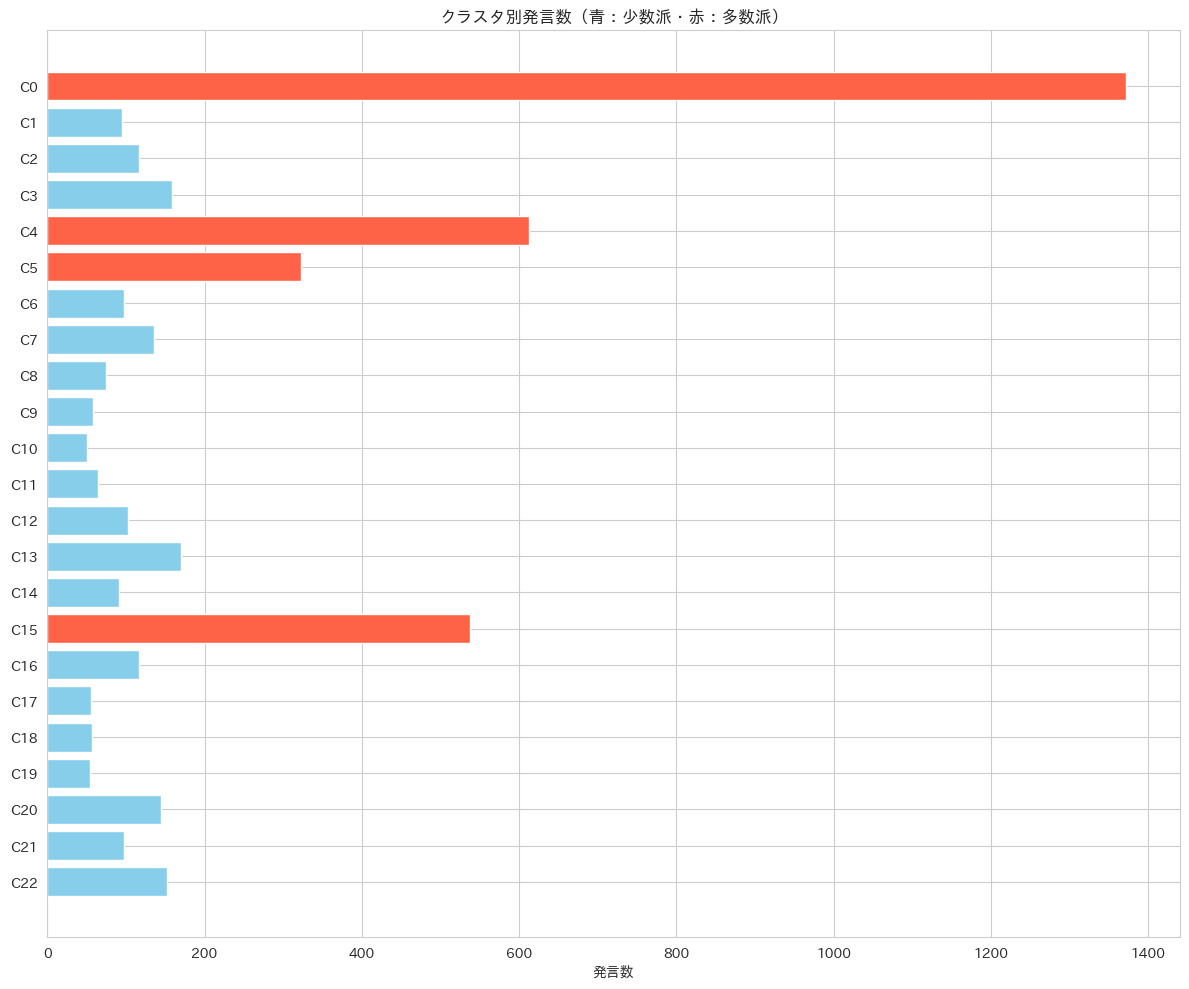

保存完了: ../data/cluster_summary.png


In [39]:
# ============================================================
# まとめ：クラスタ別発言数を可視化
# ============================================================

fig, ax = plt.subplots(figsize=(12, 10))

cluster_counts = df[df["cluster_r5"] != -1]["cluster_r5"].value_counts().sort_index()
colors = ["skyblue" if c in minority_clusters else "tomato" for c in cluster_counts.index]

ax.barh(
    [f"C{c}" for c in cluster_counts.index],
    cluster_counts.values,
    color=colors
)
ax.set_title("クラスタ別発言数（青：少数派・赤：多数派）")
ax.set_xlabel("発言数")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("../data/cluster_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/cluster_summary.png")

### 「少数派」の定義
本分析での少数派とは**意見の多様性における少数意見グループ**を指す。
具体的にはHDBSCANで検出されたクラスタのうち件数が200件以下のものを少数派と定義した。
DEI文脈での属性的少数派（障害者・外国人・女性等）とは異なる概念であることに注意。
ただし分析結果を見ると、少数派クラスタにはジェンダーギャップ・LGBT・
国際的なジェンダー平等など専門的・具体的なDEIトピックが集中しており、
属性的少数派の声と意見的少数派が重なっている傾向が見られる。

### クラスタ別発言数の考察
- C0（1,372件）・C4（613件）・C15（537件）・C5（323件）が多数派の大きなクラスタ
- 少数派クラスタ（青）は50〜200件程度に分散
- 多数決的な分析ではC0・C4・C15の意見が支配的になるが
  HDBSCANにより少数派の声を独立したグループとして検出できている
- これが本課題の要件「少数派の意見も公平に認識」を実現している